In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor , plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error , r2_score

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor


In [25]:
data = fetch_california_housing(as_frame=True)
X_train , X_test , y_train , y_test = train_test_split(
 data.data , data.target , test_size =0.2 , random_state =42
)


## Decision tree


Tree RMSE for max depth 3: 0.8015


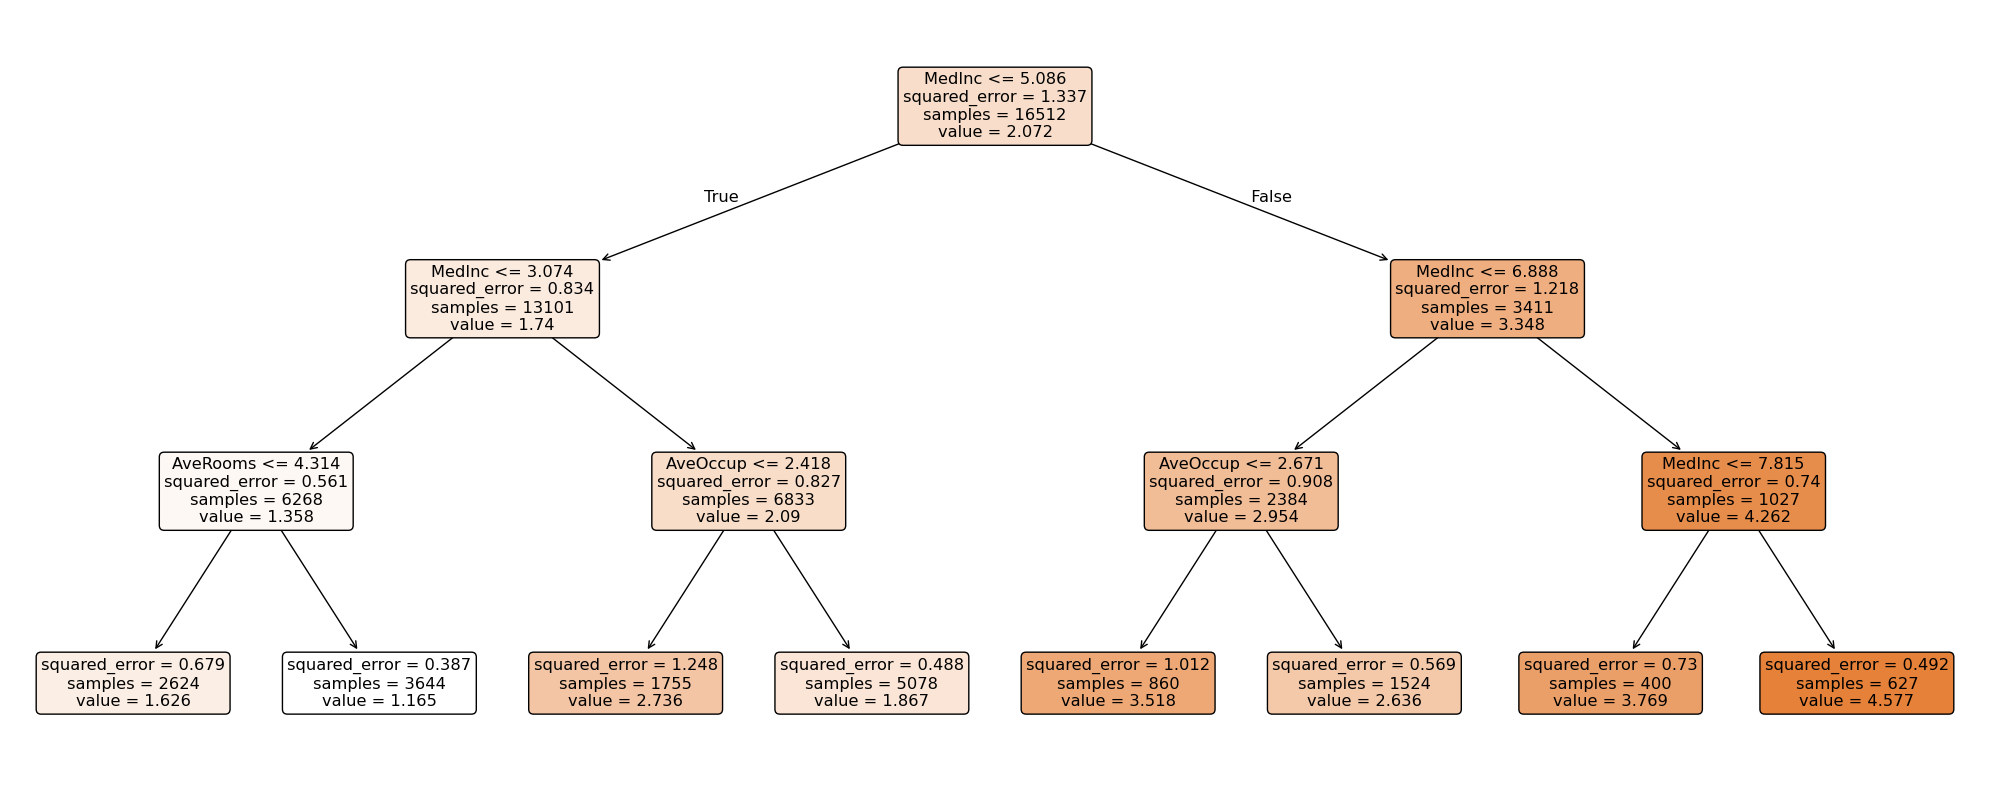

Tree RMSE for max depth 5: 0.7242


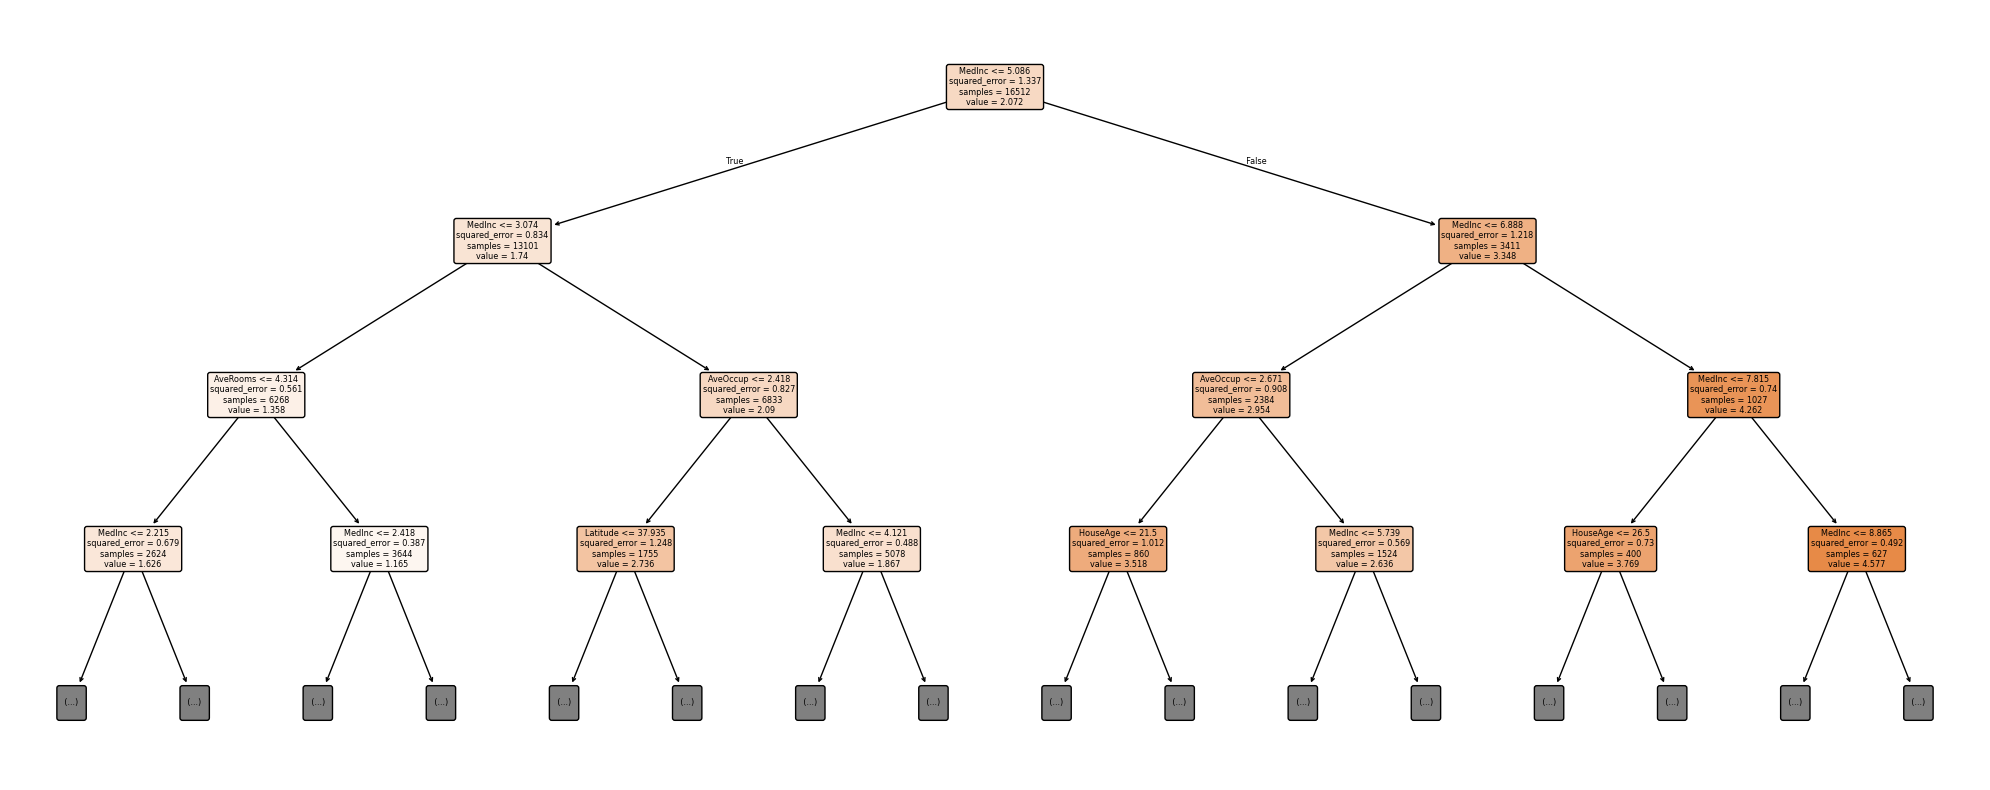

Tree RMSE for max depth 10: 0.6446


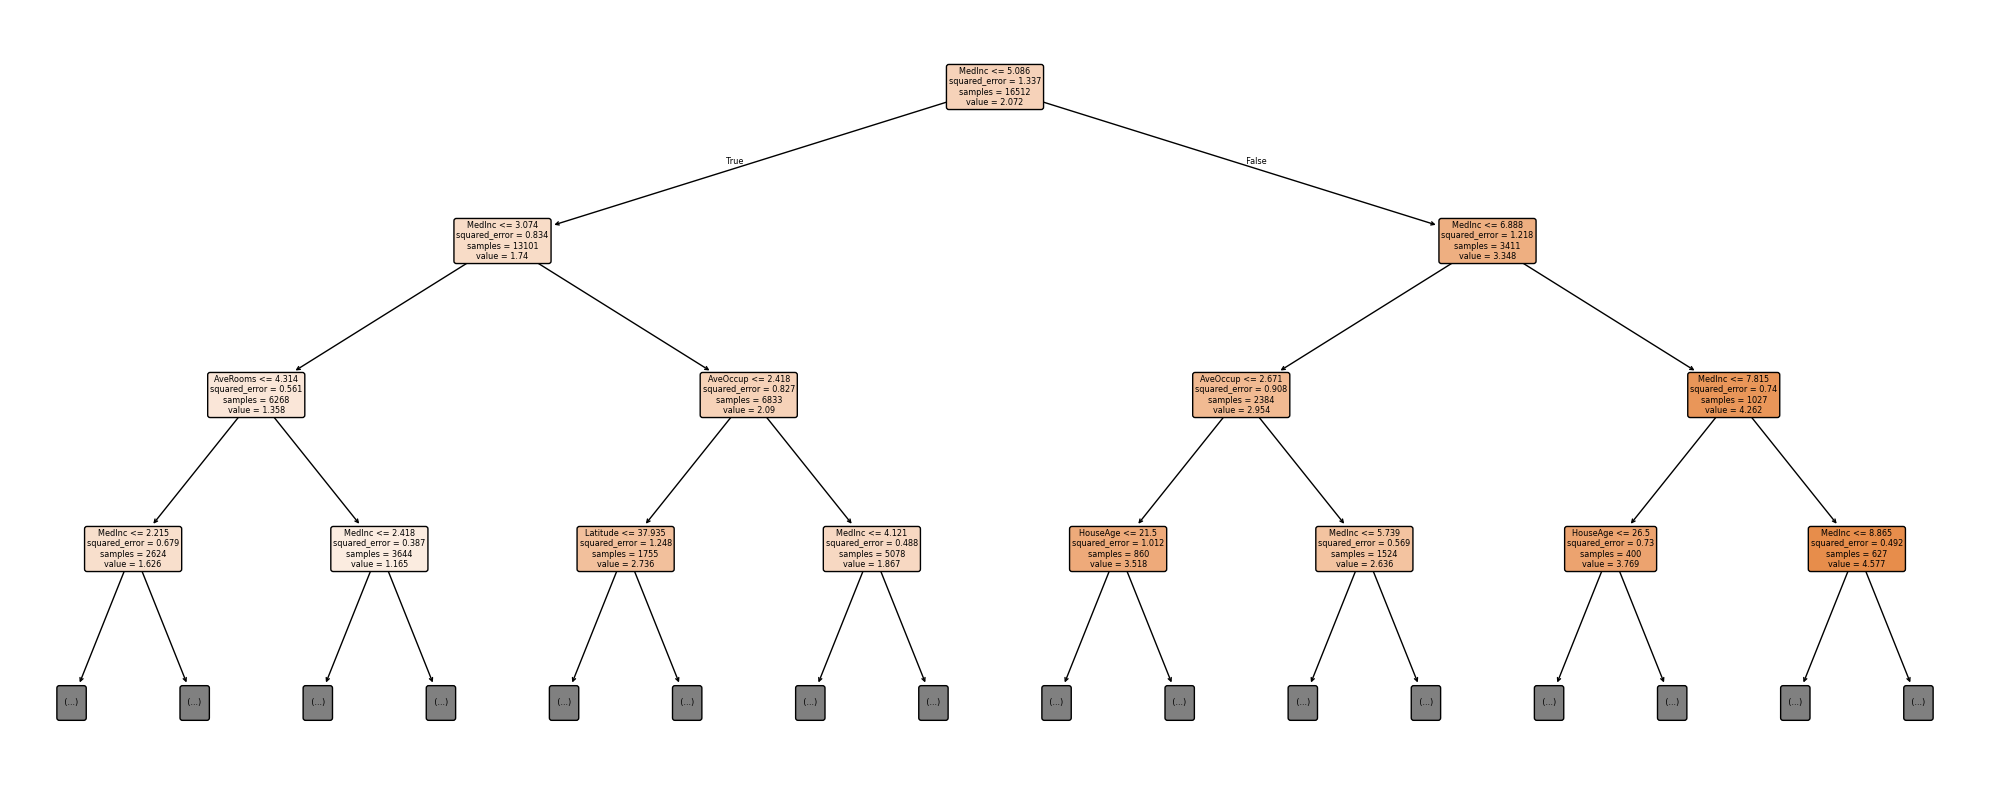

Tree RMSE for max depth None: 0.7037


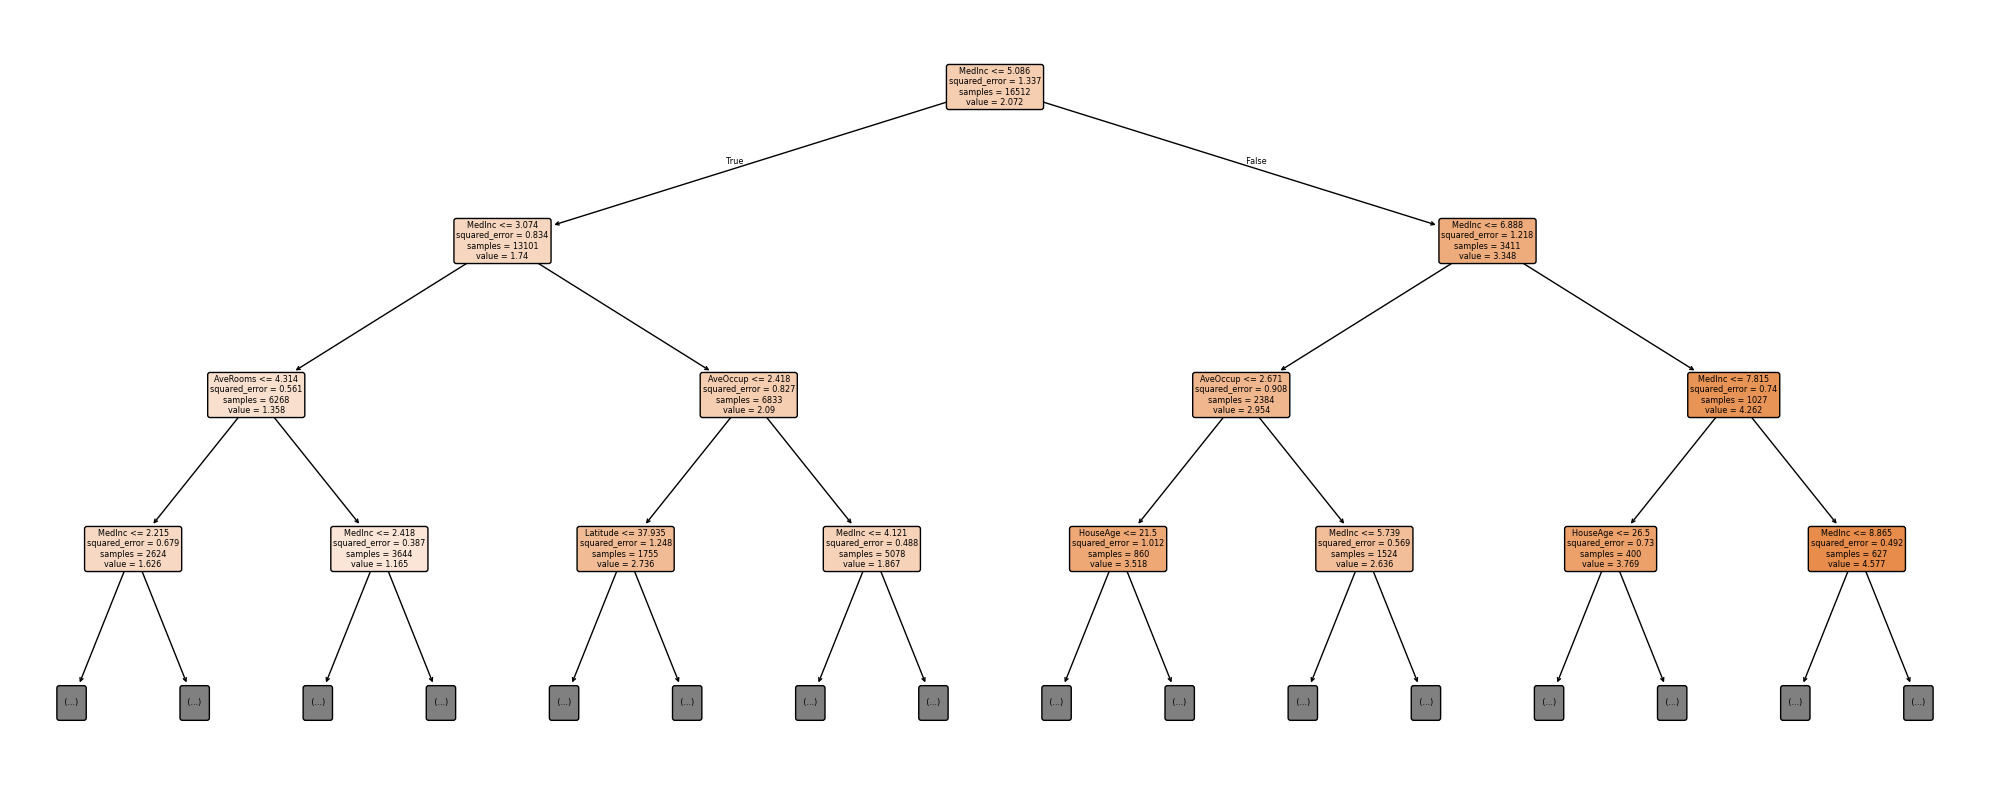

In [26]:
depth = [3, 5, 10, None]
for x in depth:
    tree = DecisionTreeRegressor (max_depth = x, random_state =42)
    tree.fit(X_train , y_train)
    y_pred = tree.predict(X_test)
    print(f"Tree RMSE for max depth {x}: {np.sqrt(mean_squared_error(y_test , y_pred)):.4f}")

    plt.figure(figsize=(20, 8))
    plot_tree (tree , feature_names =data.feature_names , filled=True , rounded=True , max_depth =3)
    plt. tight_layout ()
    plt.show ()



## Random Forest


RF RMSE (estimators: 100): 0.5115
OOB Score (estimators: 100): 0.8043


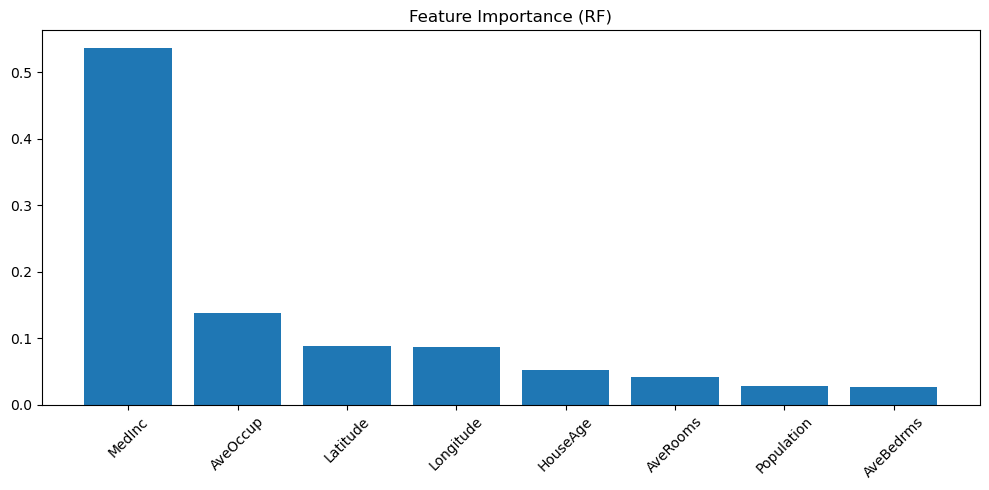

RF RMSE (estimators: 200): 0.5095
OOB Score (estimators: 200): 0.8070


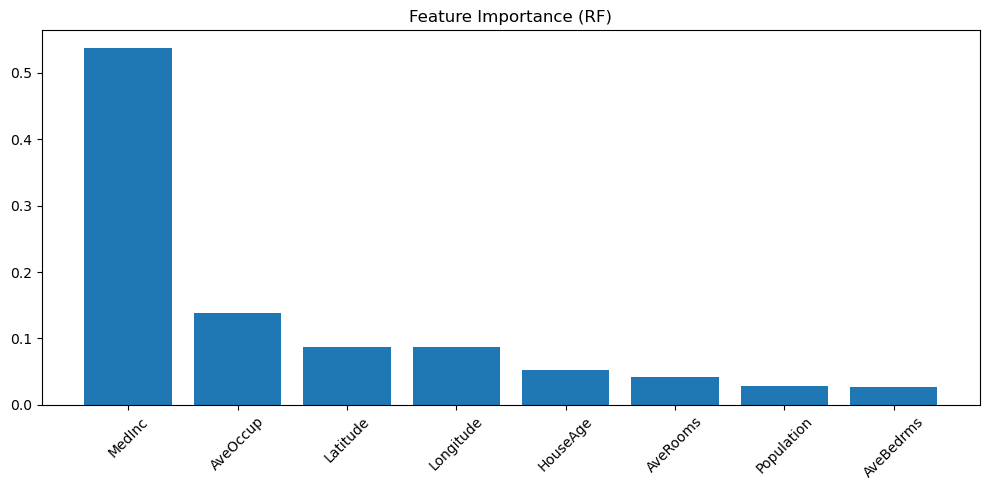

RF RMSE (estimators: 500): 0.5079
OOB Score (estimators: 500): 0.8094


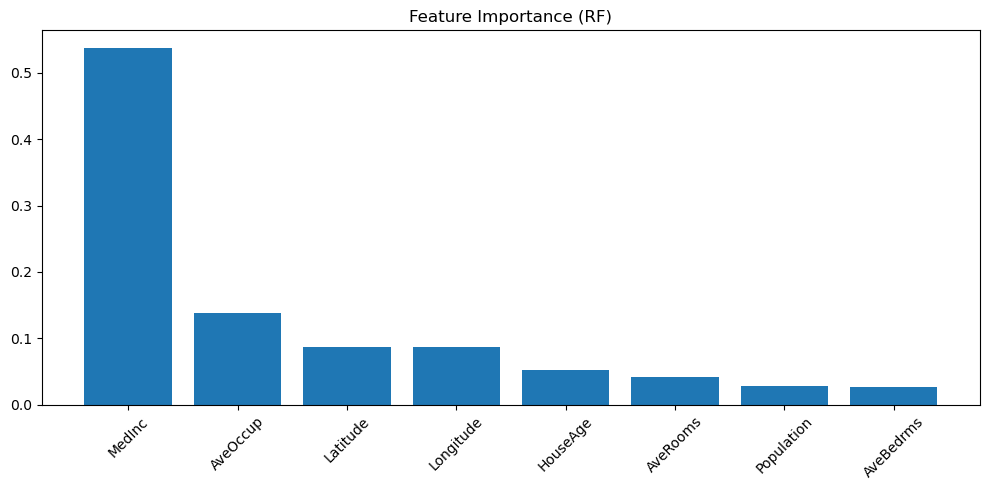

In [27]:
estimators = [100, 200, 500]

for x in estimators:
    rf = RandomForestRegressor ( n_estimators = x , max_depth =15,oob_score =True , random_state =42)
    rf.fit(X_train , y_train)
    y_pred_rf = rf.predict(X_test)
    print(f"RF RMSE (estimators: {x}): {np.sqrt(mean_squared_error(y_test , y_pred_rf)):.4f}")
    print(f"OOB Score (estimators: {x}): {rf.oob_score_:.4f}")

    imp = rf. feature_importances_
    idx = np.argsort(imp)[:: -1]
    plt.figure(figsize =(10 , 5))
    plt.bar(range(len(idx)), imp[idx ])
    plt.xticks(range(len(idx)),
    [data. feature_names [i] for i in idx], rotation =45)
    plt.title("Feature Importance (RF)")
    plt. tight_layout ()
    plt.show()


## XGBoost, LGBM, CatBoost


In [28]:
xgb_model = xgb. XGBRegressor (n_estimators =300 , max_depth =6, learning_rate =0.1 ,
                               subsample =0.8 , colsample_bytree =0.8 , random_state =42
                            )
xgb_model .fit(X_train , y_train ,eval_set =[( X_test , y_test)], verbose=False)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [29]:
lgb_model = lgb. LGBMRegressor (
    n_estimators =300 , num_leaves =31,
    learning_rate =0.1 , random_state =42
)
lgb_model .fit(X_train , y_train ,
    eval_set =[( X_test , y_test)])


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003411 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[LightGBM] [Info] Start training from score 2.071947


LGBMRegressor(n_estimators=300, random_state=42)

In [30]:
cb_model = CatBoostRegressor (
    iterations =300 , depth =6, learning_rate =0.1 ,
    random_seed =42, verbose =0
)
cb_model.fit(X_train , y_train , eval_set =( X_test , y_test))


CatBoostRegressor(depth=6, iterations=300, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=0)

XGB   RMSE=0.4501


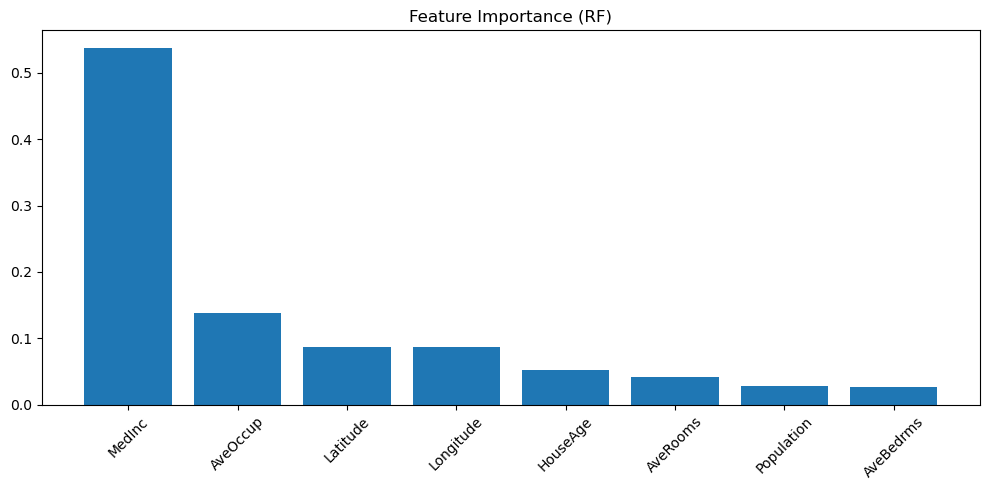

LGB   RMSE=0.4404


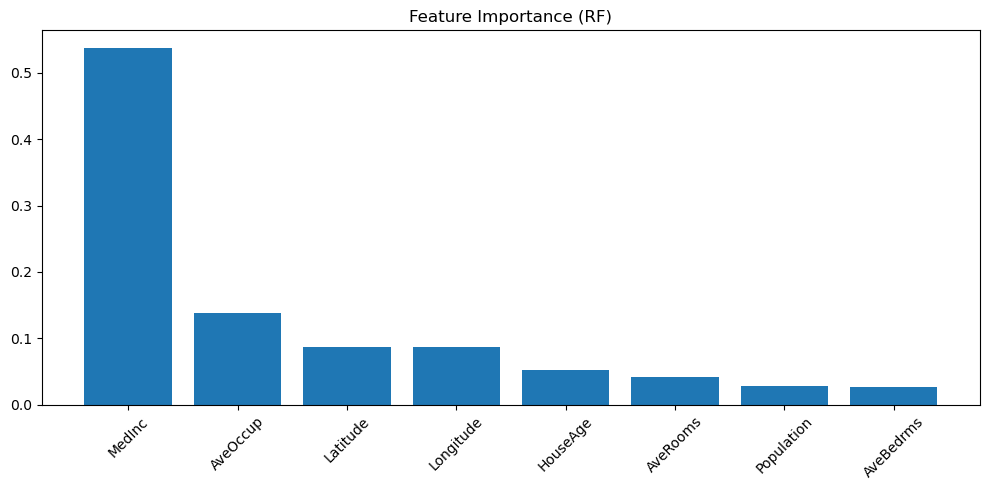

CB    RMSE=0.4657


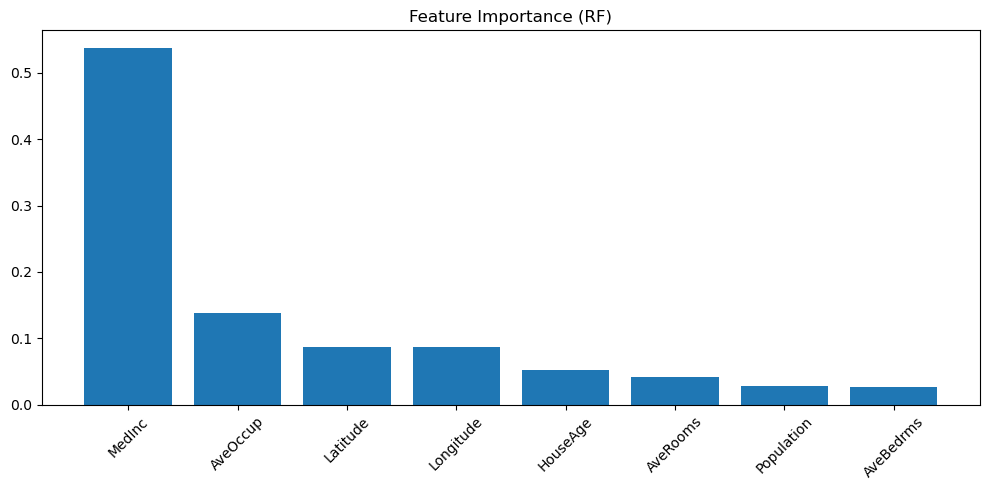

In [31]:
for name , m in [("XGB", xgb_model ), ("LGB", lgb_model ),
    ("CB", cb_model)]:
    pred = m.predict(X_test)
    rmse = np.sqrt( mean_squared_error (y_test , pred))
    print(f"{name:5s} RMSE={rmse:.4f}")

    imp = rf. feature_importances_
    idx = np.argsort(imp)[:: -1]
    plt.figure(figsize =(10 , 5))
    plt.bar(range(len(idx)), imp[idx ])
    plt.xticks(range(len(idx)),
    [data. feature_names [i] for i in idx], rotation =45)
    plt.title("Feature Importance (RF)")
    plt. tight_layout ()
    plt.show()


## Train/test RMSE for the decision trees


In [32]:
tree_comparison = []
for depth in [3, 5, 10, None]:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    tree_comparison.append({
        "max_depth": depth,
        "train_RMSE": mean_squared_error(y_train, model.predict(X_train)) ** 0.5,
        "test_RMSE": mean_squared_error(y_test, model.predict(X_test)) ** 0.5,
    })
pd.DataFrame(tree_comparison)


,max_depth,train_RMSE,test_RMSE
0,3.0,7.859567e-01,0.801505
1,5.0,6.959478e-01,0.724234
2,10.0,4.699636e-01,0.644568
3,NaN,3.218326e-16,0.703729


## Early stopping and consolidated model comparison


In [ ]:
import time
from sklearn.model_selection import train_test_split

X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)
comparison_rows = []
comparison_models = {}

def record_model(name, model, fit_seconds):
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    comparison_rows.append({
        "Model": name,
        "Train RMSE": mean_squared_error(y_train, train_prediction) ** 0.5,
        "Test RMSE": mean_squared_error(y_test, test_prediction) ** 0.5,
        "Test MAE": np.mean(np.abs(y_test - test_prediction)),
        "Test R2": r2_score(y_test, test_prediction),
        "Fit time (seconds)": fit_seconds,
    })
    comparison_models[name] = model

for depth in [3, 5, 10, None]:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    record_model(f"Decision Tree (depth={depth})", model, time.perf_counter() - start)

for n_trees in [100, 200, 500]:
    model = RandomForestRegressor(
        n_estimators=n_trees, max_depth=15, oob_score=True,
        random_state=42, n_jobs=-1
    )
    start = time.perf_counter()
    model.fit(X_train, y_train)
    record_model(f"Random Forest ({n_trees} trees)", model, time.perf_counter() - start)

xgb_early = xgb.XGBRegressor(
    n_estimators=2000, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror",
    eval_metric="rmse", early_stopping_rounds=50,
    random_state=42, n_jobs=-1
)
start = time.perf_counter()
xgb_early.fit(X_fit, y_fit, eval_set=[(X_valid, y_valid)], verbose=False)
record_model("XGBoost (early stopping)", xgb_early, time.perf_counter() - start)

lgb_early = lgb.LGBMRegressor(
    n_estimators=2000, num_leaves=31, learning_rate=0.05,
    random_state=42, n_jobs=-1, verbosity=-1
)
start = time.perf_counter()
lgb_early.fit(
    X_fit, y_fit, eval_set=[(X_valid, y_valid)],
    callbacks=[lgb.early_stopping(50, verbose=False)]
)
record_model("LightGBM (early stopping)", lgb_early, time.perf_counter() - start)

cb_early = CatBoostRegressor(
    iterations=2000, depth=6, learning_rate=0.05,
    random_seed=42, verbose=0, early_stopping_rounds=50
)
start = time.perf_counter()
cb_early.fit(X_fit, y_fit, eval_set=(X_valid, y_valid), verbose=False)
record_model("CatBoost (early stopping)", cb_early, time.perf_counter() - start)

comparison_df = pd.DataFrame(comparison_rows).sort_values("Test RMSE").reset_index(drop=True)
display(comparison_df)


,Model,Train RMSE,Test RMSE,Test MAE,Test R2,Fit time (seconds)
0,LightGBM (early stopping),2.879714e-01,0.436862,0.288224,0.854360,5.065858
1,XGBoost (early stopping),2.579677e-01,0.439167,0.287809,0.852819,5.364016
2,CatBoost (early stopping),3.283653e-01,0.440075,0.289444,0.852210,21.277987
3,Random Forest (500 trees),2.373117e-01,0.507857,0.331368,0.803177,24.935448
4,Random Forest (200 trees),2.383192e-01,0.509472,0.332177,0.801923,9.312854
5,Random Forest (100 trees),2.405422e-01,0.511471,0.333221,0.800366,4.958028
6,Decision Tree (depth=10),4.699636e-01,0.644568,0.433203,0.682948,0.212734
7,Decision Tree (depth=None),3.218326e-16,0.703729,0.454679,0.622076,0.273740
8,Decision Tree (depth=5),6.959478e-01,0.724234,0.522259,0.599732,0.102957
9,Decision Tree (depth=3),7.859567e-01,0.801505,0.597828,0.509763,0.056565


## Ensemble feature importance


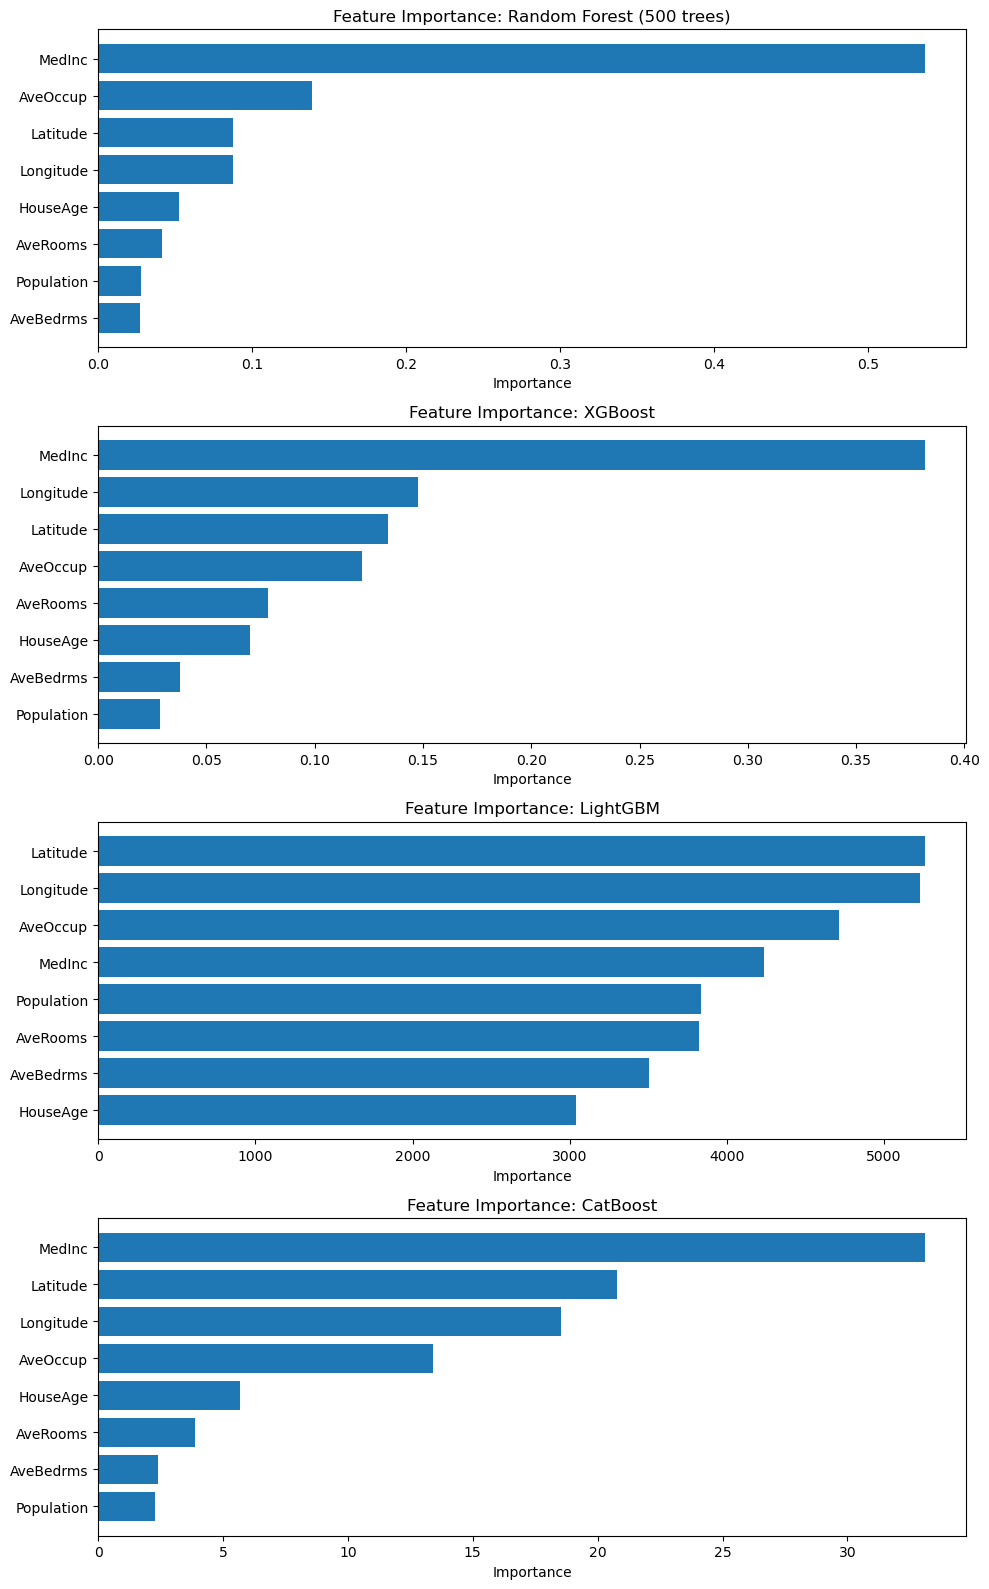

In [34]:
ensemble_models = {
    "Random Forest (500 trees)": comparison_models["Random Forest (500 trees)"],
    "XGBoost": xgb_early,
    "LightGBM": lgb_early,
    "CatBoost": cb_early,
}
fig, axes = plt.subplots(len(ensemble_models), 1, figsize=(10, 16))
for ax, (name, model) in zip(axes, ensemble_models.items()):
    importances = model.feature_importances_
    order = np.argsort(importances)
    ax.barh(np.array(data.feature_names)[order], importances[order])
    ax.set_title(f"Feature Importance: {name}")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


## Learning curve for the best model

The best model is selected by test RMSE here to satisfy the assignment comparison. For unbiased model selection, choose it using validation or cross-validation instead.


Best model by test RMSE: LightGBM (early stopping)


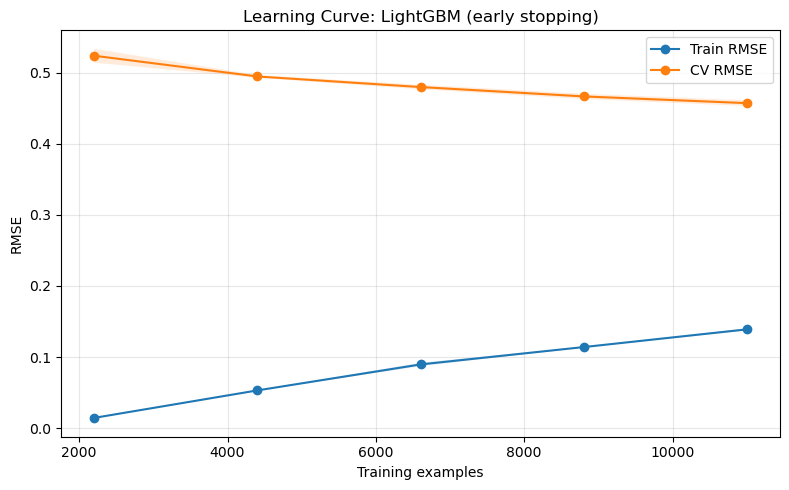

In [35]:
from sklearn.base import clone
from sklearn.model_selection import learning_curve

best_name = comparison_df.iloc[0]["Model"]
best_model = comparison_models[best_name]
print(f"Best model by test RMSE: {best_name}")

train_sizes, train_scores, validation_scores = learning_curve(
    clone(best_model), X_train, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5), cv=3,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
train_rmse = -train_scores
validation_rmse = -validation_scores
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse.mean(axis=1), marker="o", label="Train RMSE")
plt.fill_between(
    train_sizes,
    train_rmse.mean(axis=1) - train_rmse.std(axis=1),
    train_rmse.mean(axis=1) + train_rmse.std(axis=1), alpha=0.15
)
plt.plot(train_sizes, validation_rmse.mean(axis=1), marker="o", label="CV RMSE")
plt.fill_between(
    train_sizes,
    validation_rmse.mean(axis=1) - validation_rmse.std(axis=1),
    validation_rmse.mean(axis=1) + validation_rmse.std(axis=1), alpha=0.15
)
plt.xlabel("Training examples")
plt.ylabel("RMSE")
plt.title(f"Learning Curve: {best_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
